# PyTorch and Artificial Neural Networks

**DCS 404 · Data Science and Machine Learning**

---

The Neural Networks module built everything from raw NumPy: a forward pass, a hand-derived backward pass,
a from-scratch Adam optimizer, and a numerical gradient check to prove it all worked. That was worth doing
once, by hand — it's the only way to actually *see* what a framework does for you. It is not, however, how
anyone trains a real network day to day. Real work uses a **framework**: a library that turns "define the
layers, define the loss" into a trained model, handling the chain rule, the optimizer bookkeeping, and the
GPU dispatch automatically.

This module introduces **PyTorch**, the framework this course uses from here on. We'll confirm, concretely,
that its automatic differentiation produces the *exact same gradients* the Neural Networks module derived by
hand — so you can trust it as more than a black box — and then use it to train an artificial neural network
on a real dataset for the first time: **MNIST**, 70,000 handwritten digits, the "hello world" of deep
learning.

## How to work through this

Run every code cell in order (`Shift + Enter`); later cells depend on earlier ones. This module assumes
you've completed the Neural Networks module — we'll refer back to its notation, its hand-derived gradients,
and its from-scratch MLP throughout, rather than re-deriving anything from first principles.

One new thing to expect: the **MNIST dataset downloads the first time you run the Setup cell** (about 11MB,
cached afterward by `torchvision` so it won't download again). Everything else runs in a few seconds on a
laptop CPU — no GPU required, though we'll show how to use one if you have it.

## Learning objectives

After completing this module you will be able to:

- Explain what a tensor is, create tensors several ways, and perform the core operations (arithmetic,
  matrix multiplication, indexing) PyTorch shares with NumPy.
- Use **autograd** (`requires_grad`, `.backward()`, `.grad`) to compute gradients automatically, and verify it
  against a hand-derived gradient from the Neural Networks module.
- Build the same network three ways in PyTorch — `nn.Sequential`, the functional API, and `nn.Module`
  subclassing — and explain when each is the right tool.
- Load a real dataset with `torchvision.datasets` and `DataLoader`, and explain what a `DataLoader` does that
  raw NumPy slicing doesn't.
- Train an artificial neural network end to end in PyTorch: define a model, choose `CrossEntropyLoss` and
  `Adam`, and write the `zero_grad` / `backward` / `step` training loop.
- Evaluate a trained classifier with test accuracy, a confusion matrix, and a look at what it gets wrong.
- Write device-agnostic PyTorch code (`torch.device`, `.to(device)`) and explain when a GPU actually helps.

## Setup

Run this once. Libraries, the usual plotting style, a fixed seed, and the device PyTorch will train on.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import accuracy_score, confusion_matrix

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
sns.set_palette("deep")
RANDOM_STATE = 0
torch.manual_seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available()
                       else "mps" if torch.backends.mps.is_available()
                       else "cpu")
print(f"PyTorch {torch.__version__}, training on: {device}")

PyTorch 2.13.0, training on: mps


In [2]:
def data_root(name):
    '''Mirror the course's data/ -> notebooks/data/ fallback, torchvision-style.'''
    for base in ["data", "notebooks/data"]:
        if Path(base).is_dir():
            return Path(base) / name
    return Path("notebooks/data") / name   # first run in a fresh checkout: create it here

MNIST_ROOT = data_root("mnist")
transform = transforms.Compose([transforms.ToTensor()])

train_data = datasets.MNIST(root=MNIST_ROOT, train=True, download=True, transform=transform)
test_data = datasets.MNIST(root=MNIST_ROOT, train=False, download=True, transform=transform)

print(f"MNIST cached at: {MNIST_ROOT.resolve()}")
print(f"train: {len(train_data)}   test: {len(test_data)}")

MNIST cached at: /Users/aayush/Documents/Kings/AI/DCS404/notebooks/data/mnist
train: 60000   test: 10000


---
## 1. Tensors: NumPy arrays with superpowers

PyTorch's core data structure is the **tensor**, and the honest way to think about it is: a NumPy array that
can also live on a GPU and remember how it was computed (Section 2). Every NumPy habit from the Neural
Networks module transfers directly.

In [3]:
zeros = torch.zeros(3, 3)
ones = torch.ones(2, 4)
uniform = torch.rand(2, 2)          # uniform on [0, 1)
normal = torch.randn(2, 2)          # standard normal, mean 0 variance 1
ranged = torch.arange(6)

print("zeros:\n", zeros)
print("uniform:\n", uniform)
print("normal:\n", normal)
print("arange:", ranged, " shape:", ranged.shape, " dtype:", ranged.dtype)

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])
uniform:
 tensor([[0.4963, 0.7682],
        [0.0885, 0.1320]])
normal:
 tensor([[-2.1788,  0.5684],
        [-1.0845, -1.3986]])
arange: tensor([0, 1, 2, 3, 4, 5])  shape: torch.Size([6])  dtype: torch.int64


Arithmetic, matrix multiplication and indexing all read exactly like NumPy:

In [4]:
a = torch.rand(3, 3)
b = torch.rand(3, 3)
print("elementwise sum:\n", a + b)

# The matrix multiply from every forward pass in the Neural Networks module: X @ W
X = torch.rand(2, 3)      # 2 samples, 3 features
W = torch.rand(3, 4)      # 3 inputs -> 4 hidden units
print("X @ W shape:", (X @ W).shape)   # torch.matmul(X, W) works identically

grid = torch.arange(16).view(4, 4)     # .view() reshapes, like NumPy's .reshape()
print("grid:\n", grid)
print("column 3:", grid[:, 3])
print("row 2:   ", grid[2, :])

elementwise sum:
 tensor([[0.9375, 0.5660, 1.1680],
        [0.9379, 1.2506, 1.7527],
        [0.1972, 0.4675, 1.0550]])
X @ W shape: torch.Size([2, 4])
grid:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]])
column 3: tensor([ 3,  7, 11, 15])
row 2:    tensor([ 8,  9, 10, 11])


One difference worth flagging immediately, because it will matter the moment we start training: a tensor
created with `torch.rand`/`torch.randn`/etc. is a plain number container, exactly like a NumPy array — it has
no idea it might later be part of a gradient computation. Section 2 introduces the one flag that changes that.

---
## 2. Autograd: gradients without deriving them by hand

The Neural Networks module spent an entire section deriving $\frac{\partial L}{\partial w}$ by hand for a
single sigmoid neuron, then double-checked the derivation against finite differences. PyTorch's **autograd**
engine computes exactly that gradient automatically, for a network of any size, the moment you call
`.backward()`. The only thing you have to do differently is tell PyTorch which tensors you want gradients
*with respect to*, using `requires_grad=True`.

Let's rebuild the *exact same toy example* from the Neural Networks module's computational-graph section —
same weights, same inputs, same label — and check that autograd lands on the identical numbers we derived by
hand there.

In [5]:
# The same toy neuron as the Neural Networks module: z = w0 + w1*x1 + w2*x2, sigmoid, BCE loss
w0 = torch.tensor(0.10, requires_grad=True)
w1 = torch.tensor(0.40, requires_grad=True)
w2 = torch.tensor(-0.20, requires_grad=True)
x1, x2, y_true = 2.0, 3.0, 1.0

z = w0 + w1 * x1 + w2 * x2
y_hat = torch.sigmoid(z)
L = -(y_true * torch.log(y_hat) + (1 - y_true) * torch.log(1 - y_hat))

L.backward()   # walks the graph backward, exactly like Section 3-4 of the Neural Networks module

print(f"z = {z.item():.4f}   y_hat = {y_hat.item():.4f}   L = {L.item():.4f}")
print(f"autograd gradients:  dL/dw0 = {w0.grad.item():.4f}   "
      f"dL/dw1 = {w1.grad.item():.4f}   dL/dw2 = {w2.grad.item():.4f}")
print("(compare against the Neural Networks module's Section 3: "
      "-0.4256, -0.8511, -1.2767 -- the same numbers, computed automatically)")

z = 0.3000   y_hat = 0.5744   L = 0.5544
autograd gradients:  dL/dw0 = -0.4256   dL/dw1 = -0.8511   dL/dw2 = -1.2767
(compare against the Neural Networks module's Section 3: -0.4256, -0.8511, -1.2767 -- the same numbers, computed automatically)


Every digit matches. Autograd isn't a different, approximate way of getting the gradient — it's a general
implementation of the same chain-rule bookkeeping the Neural Networks module did by hand, tracking every
operation performed on a `requires_grad=True` tensor into a graph (Section 3 of that module, but built
automatically instead of drawn on paper) and walking it backward on `.backward()`. Two housekeeping details
that follow directly from how it works:

- **Gradients accumulate.** Calling `.backward()` twice *adds* to `.grad` rather than replacing it — useful
  for gradient accumulation across mini-batches, a footgun if you forget to reset it. Every training loop in
  this module calls `optimizer.zero_grad()` before each `.backward()` for exactly this reason.
- **`.backward()` only works on a scalar** (like our loss `L`). For a batch of many losses, reduce to a
  single number first — `nn.CrossEntropyLoss`, used from Section 5 onward, already averages over the batch
  for you.

---
## 3. Three ways to build a network in PyTorch

Every network so far in this course — the Neural Networks module's from-scratch MLP included — was really
just a sequence of "linear transform, then activation" blocks. PyTorch gives you three ways to express that,
trading convenience for flexibility. We'll build the *same* tiny network (4 inputs, one hidden layer of 5
ReLU units, 3 output classes) all three ways.

**`nn.Sequential`** — a straight stack of layers, nothing branching or shared. The fastest way to write a
plain feedforward network:

In [6]:
model_sequential = nn.Sequential(
    nn.Linear(4, 5),
    nn.ReLU(),
    nn.Linear(5, 3),
)
print(model_sequential)
print("output shape:", model_sequential(torch.randn(8, 4)).shape)   # 8 samples through the network

Sequential(
  (0): Linear(in_features=4, out_features=5, bias=True)
  (1): ReLU()
  (2): Linear(in_features=5, out_features=3, bias=True)
)
output shape: torch.Size([8, 3])


**The functional API** — build the parameters yourself (`requires_grad=True` tensors, exactly like Section 2)
and call `torch.nn.functional` operations on them directly. More typing, but it makes explicit exactly what
`nn.Linear` was hiding: a weight matrix, a bias vector, and a matrix multiply.

In [7]:
# Same architecture, built by hand: weight shape is (out_features, in_features)
W1 = torch.randn(5, 4, requires_grad=True)
b1 = torch.randn(5, requires_grad=True)
W2 = torch.randn(3, 5, requires_grad=True)
b2 = torch.randn(3, requires_grad=True)

inputs = torch.randn(8, 4)
hidden = F.relu(F.linear(inputs, W1, b1))
output = F.linear(hidden, W2, b2)
print("output shape:", output.shape)

output shape: torch.Size([8, 3])


**`nn.Module` subclassing** — define the layers in `__init__`, define how they connect in `forward`. This is
the most verbose option and also the most flexible: multiple inputs or outputs, layers reused more than once,
branches that `Sequential` simply can't express. It's also the option every real PyTorch codebase reaches for
once a model is more than a straight stack, so it's the one we'll use for MNIST from Section 5 onward.

In [8]:
class TinyNet(nn.Module):
    def __init__(self, in_features, hidden_features, out_features):
        super().__init__()
        self.hidden = nn.Linear(in_features, hidden_features)
        self.output = nn.Linear(hidden_features, out_features)

    def forward(self, x):
        x = F.relu(self.hidden(x))
        x = self.output(x)
        return x

model_subclass = TinyNet(4, 5, 3)
print(model_subclass)
print("output shape:", model_subclass(torch.randn(8, 4)).shape)

TinyNet(
  (hidden): Linear(in_features=4, out_features=5, bias=True)
  (output): Linear(in_features=5, out_features=3, bias=True)
)
output shape: torch.Size([8, 3])


All three produced a network with the same shape and the same operations — `nn.Sequential` and the functional
API are really just convenience wrappers around what `nn.Module` subclassing spells out explicitly. Notice
also what none of the three needed: a hand-written `backward` method. Every `nn.Linear`, `F.relu` and
arithmetic operation above is built from `requires_grad=True` tensors under the hood, so Section 2's autograd
already knows how to differentiate through the entire model.

---
## 4. The MNIST dataset

Every dataset in this course so far has been small enough to hold entirely in memory as a NumPy array or a
pandas `DataFrame`. **MNIST** — 70,000 grayscale images of handwritten digits, 0 through 9, each 28x28 pixels
— is the point where that stops being the natural approach, and it's the dataset that convinced the field
that neural networks could solve real perception problems. We already downloaded it in the Setup cell, via
exactly the pattern this course uses for every dataset: check `data/`, then `notebooks/data/`, then fetch it
(`torchvision` handles the fetching and caching itself).

one image: type <class 'torch.Tensor'>, shape (1, 28, 28), dtype torch.float32
pixel value range: [0.0, 1.0]
label: 5


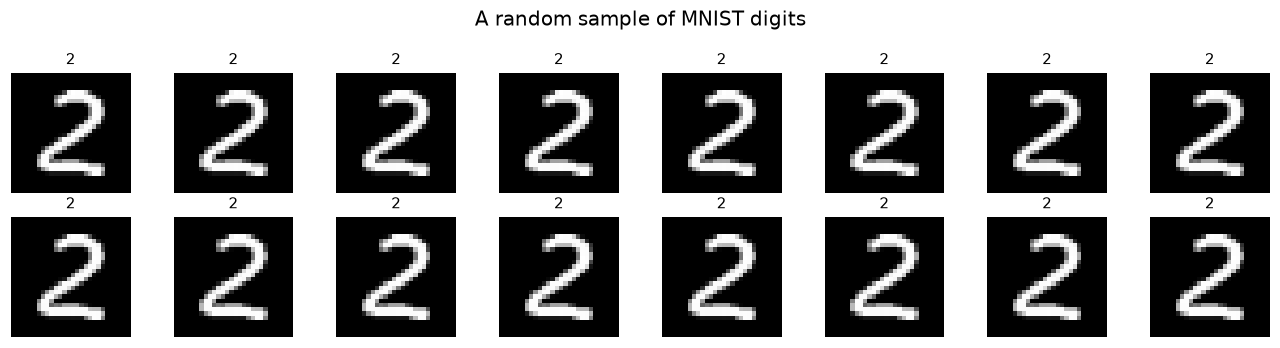

In [9]:
image, label = train_data[0]
print(f"one image: type {type(image)}, shape {tuple(image.shape)}, dtype {image.dtype}")
print(f"pixel value range: [{image.min():.1f}, {image.max():.1f}]")
print(f"label: {label}")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax in axes.ravel():
    idx = np.random.default_rng(RANDOM_STATE).integers(0, len(train_data))
    img, lbl = train_data[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(str(lbl), fontsize=10)
    ax.axis("off")
plt.suptitle("A random sample of MNIST digits")
plt.tight_layout()
plt.show()

Shape `(1, 28, 28)` reads as **(channels, height, width)** — one channel because these are grayscale, not RGB.
Every artificial neural network in this course expects a *flat* vector of features, exactly like the `X`
matrices from every earlier module, so the first thing our model will do is flatten each image into a single
784-length vector ($28\times28=784$) — throwing away the 2-D grid structure entirely. (Convolutional networks,
outside this module's scope, are the architecture built specifically to *not* throw that structure away.)

Real datasets this size are never fed to a model as one giant tensor — that would mean recomputing the
gradient over all 60,000 images before taking a single step. PyTorch's **`DataLoader`** handles the practical
side of mini-batch training we built by hand in the Neural Networks module: shuffling, batching, and handing
back one mini-batch at a time.

In [10]:
BATCH_SIZE = 128
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000, shuffle=False)

images, labels = next(iter(train_loader))
print(f"one mini-batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}")
print(f"{len(train_loader)} mini-batches per epoch over {len(train_data)} training images")

one mini-batch: images (128, 1, 28, 28), labels (128,)
469 mini-batches per epoch over 60000 training images


---
## 5. Building and training an ANN classifier

Time to put Sections 2-4 together: an `nn.Module` (Section 3's most flexible option), autograd (Section 2) for
the gradients, and mini-batches from a `DataLoader` (Section 4). The architecture is a direct descendant of
the Neural Networks module's from-scratch MLP — flatten the input, one hidden layer with ReLU, a final linear
layer — just deeper and wired up with PyTorch's building blocks instead of raw NumPy.

In [11]:
class MNIST_ANN(nn.Module):
    def __init__(self, hidden1=128, hidden2=64, n_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()                       # (batch, 1, 28, 28) -> (batch, 784)
        self.hidden1 = nn.Linear(28 * 28, hidden1)
        self.hidden2 = nn.Linear(hidden1, hidden2)
        self.output = nn.Linear(hidden2, n_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.hidden1(x))
        x = F.relu(self.hidden2(x))
        x = self.output(x)          # raw logits -- no softmax here, see the note below
        return x

model = MNIST_ANN().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"total trainable parameters: {n_params:,}")

MNIST_ANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden1): Linear(in_features=784, out_features=128, bias=True)
  (hidden2): Linear(in_features=128, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=10, bias=True)
)
total trainable parameters: 109,386


Notice `forward` returns raw, un-normalised **logits** rather than passing them through softmax. That isn't an
oversight: this is a 10-class version of the Neural Networks module's binary cross-entropy loss, and
PyTorch's **`nn.CrossEntropyLoss`** expects raw logits and applies `log_softmax` internally, in one
numerically stable step, rather than two separate ones. Written out, the loss for one example is

$$L = -\log\left(\frac{e^{z_{y}}}{\sum_{k=1}^{10} e^{z_k}}\right)$$

— softmax turns the 10 logits into class probabilities, then we take the negative log-probability the model
assigned to the *true* class $y$ — the direct multi-class generalisation of the binary cross-entropy loss from
the Neural Networks module. **`Adam`** is the optimizer that module built from scratch in its own optimization
section; here it's one line.

epoch 1/5  -  training loss: 0.4331


epoch 2/5  -  training loss: 0.1797


epoch 3/5  -  training loss: 0.1283


epoch 4/5  -  training loss: 0.0982


epoch 5/5  -  training loss: 0.0792


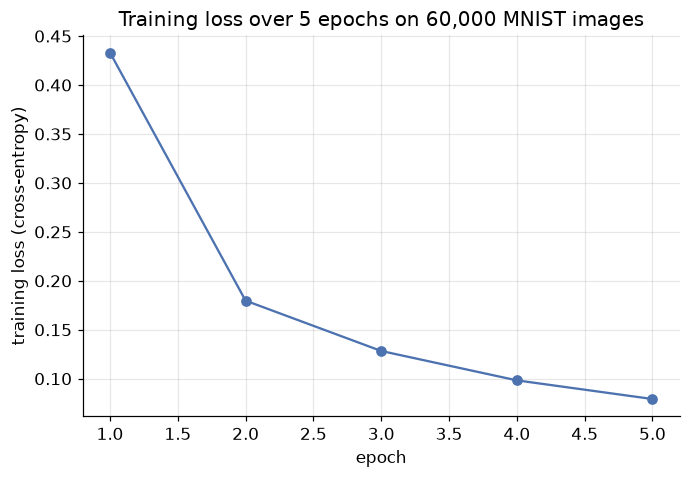

In [12]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader, loss_fn, optimizer, dev=device):
    model.train()                                  # some layers (not used here) behave differently at train time
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(dev), labels.to(dev)

        optimizer.zero_grad()                       # autograd accumulates -- always reset first (Section 2)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()                              # the entire backward pass, in one call
        optimizer.step()                              # the entire Adam update, in one call

        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

EPOCHS = 5
train_losses = []
for epoch in range(1, EPOCHS + 1):
    epoch_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, dev=device)
    train_losses.append(epoch_loss)
    print(f"epoch {epoch}/{EPOCHS}  -  training loss: {epoch_loss:.4f}")

plt.plot(range(1, EPOCHS + 1), train_losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("training loss (cross-entropy)")
plt.title("Training loss over 5 epochs on 60,000 MNIST images")
plt.show()

Four lines — `zero_grad`, forward, `backward`, `step` — replace the entire hand-written gradient-descent loop
from the Neural Networks module, and they scale unchanged from a two-feature toy dataset to 60,000 real
images with 784 features each. That's the actual payoff of a framework: not new mathematics, but the same
mathematics running on real data without hand-deriving a single gradient.

---
## 6. Evaluating the trained network

Training loss only tells us the network is fitting the data it has seen. As every module since Evaluation
Metrics has insisted, the real question is how it performs on images it never trained on.

In [13]:
def evaluate(model, loader):
    model.eval()                 # tells the model we're predicting, not training
    all_preds, all_true = [], []
    with torch.no_grad():        # no backward pass coming -- don't bother building the graph (Section 2)
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(dim=1)     # the class with the largest logit
            all_preds.append(preds.cpu())
            all_true.append(labels.cpu())
    return torch.cat(all_true).numpy(), torch.cat(all_preds).numpy()

y_true, y_pred = evaluate(model, test_loader)
test_accuracy = accuracy_score(y_true, y_pred)
print(f"test accuracy on {len(y_true):,} held-out images: {test_accuracy:.2%}")

test accuracy on 10,000 held-out images: 97.26%


A single accuracy number hides *which* digits get confused for which. A **confusion matrix** — true label
down the rows, predicted label across the columns — shows exactly that.

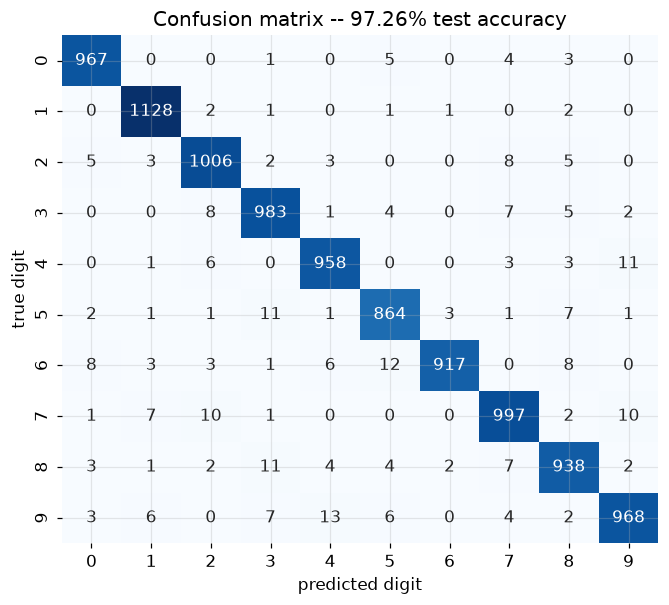

most-confused pairs (true -> predicted, count):
  true 9 -> predicted 4: 13 times
  true 6 -> predicted 5: 12 times
  true 4 -> predicted 9: 11 times
  true 8 -> predicted 3: 11 times
  true 5 -> predicted 3: 11 times


In [14]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("predicted digit"); plt.ylabel("true digit")
plt.title(f"Confusion matrix -- {test_accuracy:.2%} test accuracy")
plt.show()

# The most-confused off-diagonal pairs -- where the network's mistakes actually go
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
top_confusions = np.dstack(np.unravel_index(np.argsort(-cm_offdiag.ravel())[:5], cm_offdiag.shape))[0]
print("most-confused pairs (true -> predicted, count):")
for true_digit, pred_digit in top_confusions:
    print(f"  true {true_digit} -> predicted {pred_digit}: {cm_offdiag[true_digit, pred_digit]} times")

Almost every heavily-populated off-diagonal cell is a pair of digits that genuinely look alike in handwriting
— a poorly looped 4 read as a 9, a closed-up 5 read as a 3. That's a reassuring failure mode: the network is
making the same kind of mistakes a person squinting at messy handwriting would make, not something arbitrary.
Let's look at some of those mistakes directly.

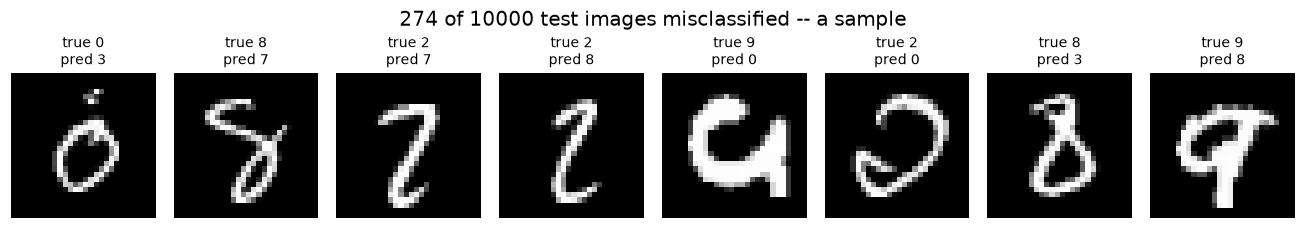

In [15]:
misclassified = np.nonzero(y_true != y_pred)[0]
rng = np.random.default_rng(RANDOM_STATE)
show_idx = rng.choice(misclassified, size=min(8, len(misclassified)), replace=False)

fig, axes = plt.subplots(1, len(show_idx), figsize=(12, 2.2))
for ax, idx in zip(axes, show_idx):
    img, _ = test_data[idx]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"true {y_true[idx]}\npred {y_pred[idx]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"{len(misclassified)} of {len(y_true)} test images misclassified -- a sample")
plt.tight_layout()
plt.show()

---
## 7. Device-agnostic code, and when a GPU actually helps

Every model and mini-batch above was already moved with `.to(device)`, where `device` was chosen once in the
Setup cell:

```python
device = torch.device("cuda" if torch.cuda.is_available()
                       else "mps" if torch.backends.mps.is_available()
                       else "cpu")
```

`"cuda"` is an NVIDIA GPU, `"mps"` is Apple Silicon's GPU, and `"cpu"` is always available. Writing code this
way — never hard-coding `"cuda"` or `"cpu"` — means the exact same notebook runs unmodified on a laptop with
no GPU and on a workstation with one. This pattern, not the specific device found, is the actual habit worth
keeping.

A GPU's advantage comes from doing thousands of small arithmetic operations in parallel — a genuine win once
a layer is multiplying large matrices across large batches. It is not a universal win: moving data to the GPU
and back costs time too, and for a small network like ours (a few hundred thousand parameters, batches of
128 tiny images) that overhead can rival or exceed whatever compute time is saved. Let's measure it directly
rather than assume.

In [16]:
import time

def time_one_epoch(dev_name, loader):
    dev = torch.device(dev_name)
    timed_model = MNIST_ANN().to(dev)
    timed_optimizer = torch.optim.Adam(timed_model.parameters(), lr=1e-3)
    start = time.time()
    train_one_epoch(timed_model, loader, loss_fn, timed_optimizer, dev=dev)
    return time.time() - start

devices_to_compare = ["cpu"] + ([str(device)] if str(device) != "cpu" else [])
for dev_name in devices_to_compare:
    elapsed = time_one_epoch(dev_name, train_loader)
    print(f"{dev_name:5s}: {elapsed:.2f}s for one epoch over {len(train_data):,} images")

cpu  : 1.08s for one epoch over 60,000 images


mps  : 1.74s for one epoch over 60,000 images


Whichever device came out ahead above, the reason is the same principle: our MNIST classifier is a *small*
network on *small* (28x28) images — exactly the regime where a GPU's parallelism has the least raw arithmetic
to chew through relative to its data-transfer overhead. Convolutional networks over full-size photographs, or
the transformer architectures behind modern language models, multiply matrices orders of magnitude larger per
layer — that's where a GPU's advantage stops being a rounding error and starts being the difference between a
training run measured in minutes versus days. Writing device-agnostic code from day one means you don't have
to rewrite anything to find out which regime a future project falls into.

---
## 8. Your turn

Add cells below each exercise. Exercises 2 and 5 are the ones that consolidate the big ideas.

**Exercise 1 — Widen the network.**
Change `MNIST_ANN`'s `hidden1`/`hidden2` to larger values (e.g. 256 and 128), retrain for the same 5 epochs,
and compare test accuracy and the confusion matrix against Section 6's result. Did the extra capacity help,
hurt, or make no real difference? What would the Neural Networks module's Regularization section predict if
you kept adding capacity indefinitely?

**Exercise 2 — Verify autograd on a second gradient.**
Pick a different toy computation — e.g. $y = 3x^2 + 2x$ at $x=4$ — compute $\frac{dy}{dx}$ by hand, then
verify it with `torch.tensor(4.0, requires_grad=True)` and `.backward()`. Do the same for a two-variable
function of your choice, checking both partial derivatives against `.grad`.

**Exercise 3 — Swap the optimizer.**
Replace `torch.optim.Adam` in Section 5 with `torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)` —
the Neural Networks module's momentum optimizer, one line instead of a hand-written update rule. Retrain and
compare the training-loss curve and final test accuracy against Adam's.

**Exercise 4 — A held-out validation set.**
Section 5 trains directly against the test set's eventual evaluation, with no validation split in between —
fine for a short teaching example, not fine for real model selection. Split `train_data` into a training and
validation subset (`torch.utils.data.random_split`), track validation loss each epoch alongside training loss,
and add early stopping (Neural Networks module, Section 9) that restores the best-validation-loss weights.

**Exercise 5 — The full sweep.**
Combine Exercises 1, 3 and 4: try at least two architectures and two optimizers, each with early stopping on
a proper validation split, and report test accuracy for every combination in a table. Which combination
would you actually ship, and why — on accuracy alone, or does training time (Section 7) change your answer?

---
## 9. If you remember nothing else

1. A PyTorch **tensor** is a NumPy array that can also live on a GPU and track how it was computed — every
   NumPy habit (shapes, arithmetic, matrix multiply, indexing) transfers directly.

2. **Autograd** (`requires_grad=True`, `.backward()`, `.grad`) computes exactly the gradient the Neural
   Networks module derived by hand, automatically, for a graph of any size — verified in this module by
   reproducing that hand-derived example digit for digit.

3. A network can be built three ways — `nn.Sequential` (simple stacks), the functional API (explicit
   parameters), `nn.Module` subclassing (full flexibility) — and all three are differentiable automatically,
   with no hand-written `backward`.

4. `torchvision.datasets` plus `DataLoader` handle real-dataset practicalities (downloading, caching,
   shuffling, batching) that don't exist for a NumPy array small enough to hold in memory.

5. Training is four lines inside a loop over batches: `optimizer.zero_grad()`, forward pass, `loss.backward()`,
   `optimizer.step()` — the same gradient-descent update from every earlier module, now framework-managed.

6. `nn.CrossEntropyLoss` is binary cross-entropy's multi-class generalisation: it expects raw logits and
   applies `log_softmax` internally in one numerically stable step.

7. Evaluate with `model.eval()` and `torch.no_grad()` (no gradient bookkeeping needed for predictions), and
   read a confusion matrix, not just accuracy, to see *which* mistakes a classifier makes.

8. Write device-agnostic code (`torch.device(...)`, `.to(device)`) always — but a GPU only pays off once a
   model and its batches are large enough that parallel compute outweighs data-transfer overhead. Our small
   MNIST classifier was exactly the borderline case.

---
## 10. Further reading and glossary

### Further reading

- [PyTorch's official 60-minute blitz](https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html)
  — the canonical short tour of tensors, autograd, and training a network, covering the same ground as this
  module with additional detail.
- [PyTorch tensor documentation](https://pytorch.org/docs/stable/tensors.html) and
  [`torch.nn` documentation](https://pytorch.org/docs/stable/nn.html) — the full operation/layer reference
  for everything used above and much more.
- Yann LeCun, Corinna Cortes & Christopher Burges, [*The MNIST Database*](http://yann.lecun.com/exdb/mnist/)
  — the dataset's original page, with historical context and the accuracy achieved by decades of published
  methods.
- [`torchvision.datasets` documentation](https://pytorch.org/vision/stable/datasets.html) — every
  ready-to-download dataset bundled with `torchvision`, MNIST among dozens of others.
- The Neural Networks module (this course) — every concept here (chain rule, activation functions, Adam,
  weight initialisation, early stopping) still applies; PyTorch just automates the arithmetic.

### Glossary

| Term | Meaning |
|---|---|
| Tensor | PyTorch's core array type — a NumPy array that can live on a GPU and track its computation history. |
| `requires_grad` | A flag marking a tensor so autograd tracks operations on it for later differentiation. |
| Autograd | PyTorch's automatic differentiation engine; computes gradients via `.backward()`. |
| Computational graph | The record of operations autograd builds automatically as tensors interact (built by hand in the Neural Networks module). |
| `nn.Sequential` | A PyTorch model built as a plain stack of layers, one input, one output. |
| Functional API (`torch.nn.functional`) | Building a model from explicit parameter tensors and stateless operations. |
| `nn.Module` subclassing | Defining a model's layers in `__init__` and its computation in `forward`; the most flexible option. |
| `torchvision.datasets` | Ready-to-download computer-vision datasets (MNIST, Fashion-MNIST, CIFAR, ...), returned as PyTorch-compatible objects. |
| `DataLoader` | Wraps a dataset to handle shuffling and mini-batching during training. |
| Logits | A model's raw, un-normalised output scores, before softmax turns them into probabilities. |
| `nn.CrossEntropyLoss` | Multi-class cross-entropy loss; expects raw logits and applies `log_softmax` internally. |
| `optimizer.zero_grad()` | Resets accumulated gradients before the next `.backward()` call. |
| `model.train()` / `model.eval()` | Switches layers that behave differently at train vs. prediction time (e.g. dropout, batch norm). |
| `torch.no_grad()` | A context that skips building the computational graph, used when no `.backward()` is coming. |
| `torch.device` | An object representing where tensors/models live and compute (`"cpu"`, `"cuda"`, `"mps"`). |
| MNIST | 70,000 labelled 28x28 grayscale images of handwritten digits 0-9; the field's standard first image dataset. |